## Obtener información de pluggins instalados y demás:

        argos3 -q all

mostrará una lista completa de todos los sensores disponibles en la instalación actual de ARGoS. Incluye sensores para todos los robots registrados, no solo el Foot-Bot, pero tú podrás identificar los que aplica por nombre.

        argos3 -q sensors

Filtar solo para el Footbot

        argos3 -q sensors | grep foot-bot

Comando para convertir frames a videos:

ffmpeg -framerate 50 -start_number 000 -i ~/argos-experiments/Resultados/Robots/Qupa/Ks1/video_dem/frame/frame_%010d.png -vf "scale=trunc(iw/2)*2:trunc(ih/2)*2" -c:v libx264 -pix_fmt yuv420p -crf 18 ~/argos-experiments/Resultados/Robots/Qupa/Ks1/video_dem/Ks1.mp4 



## Graficar ecuaciones obtenidas por Regresión Lineal:

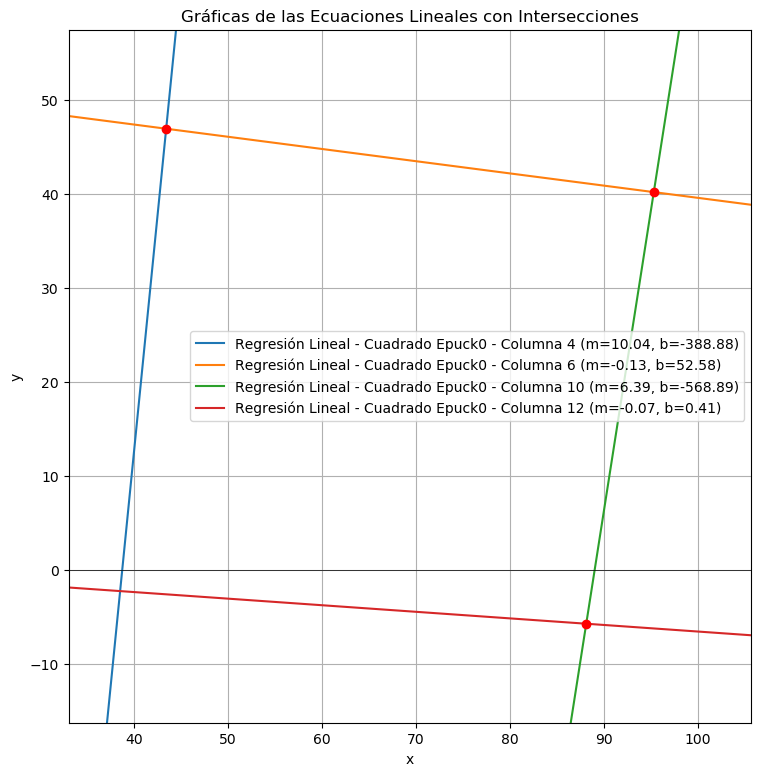

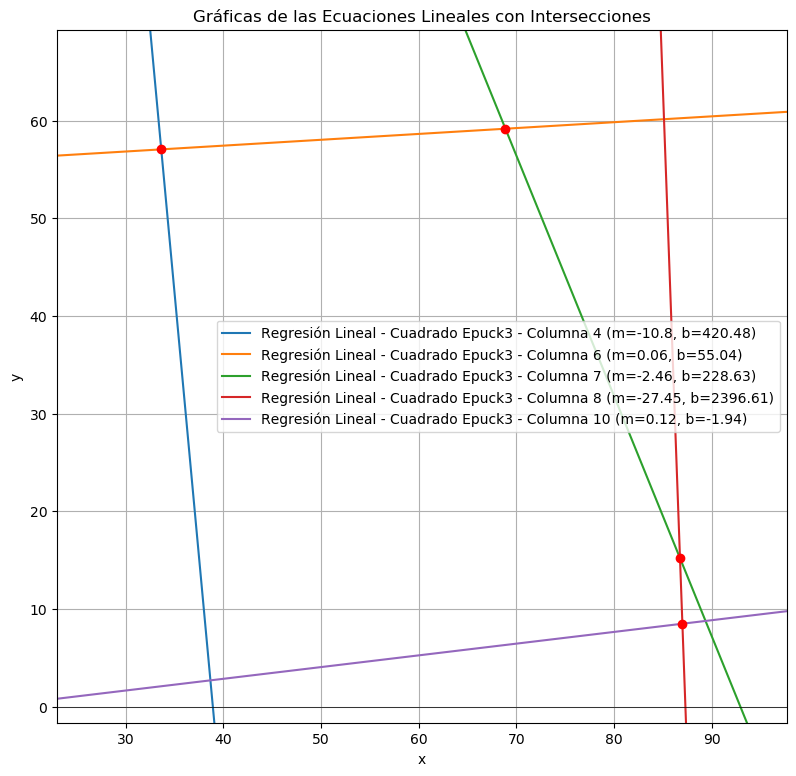

In [2]:
import numpy as np
import matplotlib.pyplot as plt



# Función para calcular la intersección entre dos rectas
def interseccion(m1, b1, m2, b2):
    # Evitar división por cero
    if m1 == m2:
        return None  # Las rectas son paralelas, no tienen intersección
    
    # Calcular el valor de x
    x_interseccion = (b2 - b1) / (m1 - m2)
    # Calcular el valor de y usando una de las ecuaciones
    y_interseccion = m1 * x_interseccion + b1
    return x_interseccion, y_interseccion

# Función para obtener la ecuación y = mx + b y graficar las rectas
def graficar_ecuaciones(ecuaciones):
    # Crear una figura para la gráfica
    plt.figure(figsize=(15, 9))
    
    # Variables para almacenar las intersecciones
    intersecciones_x = []
    intersecciones_y = []

    # Iterar sobre las ecuaciones
    for eq_set, nombre in ecuaciones:
        # Crear una lista para las ecuaciones de cada conjunto
        ecuaciones_lista = list(eq_set.items())
        
        # Iterar sobre cada par de ecuaciones sucesivas
        for i in range(len(ecuaciones_lista) - 1):
            # Obtener los coeficientes m y b de las dos rectas consecutivas
            col1, (m1, b1) = ecuaciones_lista[i]
            col2, (m2, b2) = ecuaciones_lista[i + 1]
            
            # Calcular la intersección
            interseccion_point = interseccion(m1, b1, m2, b2)
            if interseccion_point:
                intersecciones_x.append(interseccion_point[0])
                intersecciones_y.append(interseccion_point[1])
    
    # Ajustar los límites de los ejes en función de las intersecciones encontradas
    if intersecciones_x and intersecciones_y:
        x_min = min(intersecciones_x)
        x_max = max(intersecciones_x)
        y_min = min(intersecciones_y)
        y_max = max(intersecciones_y)
        
        # Ajustar los márgenes un poco para asegurarse de que no quede pegado a los bordes
        x_margin = (x_max - x_min) * 0.2
        y_margin = (y_max - y_min) * 0.2
        
        plt.xlim(x_min - x_margin, x_max + x_margin)
        plt.ylim(y_min - y_margin, y_max + y_margin)

    # Graficar todas las ecuaciones
    for eq_set, nombre in ecuaciones:
        # Iterar sobre cada ecuación (m, b) en el diccionario
        for col, (m, b) in eq_set.items():
            # Establecer el rango de x para la gráfica de la recta
            x_vals = np.linspace(min(intersecciones_x) - 30, max(intersecciones_x) + 30, 400)
            # Calcular los valores de y correspondientes para cada m y b
            y_vals = m * x_vals + b
            plt.plot(x_vals, y_vals, label=f"{nombre} - Columna {col} (m={m}, b={b})")

    # Mostrar los puntos de intersección en la gráfica
    for x, y in zip(intersecciones_x, intersecciones_y):
        plt.scatter(x, y, color='red', zorder=5)
    
    # Configuración de la gráfica
    plt.title("Gráficas de las Ecuaciones Lineales con Intersecciones")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()
    plt.grid(True)
    plt.axhline(0, color='black',linewidth=0.5)
    plt.axvline(0, color='black',linewidth=0.5)
    
    # Mostrar la gráfica
    plt.gca().set_aspect('equal', adjustable='box')  # Para mantener la escala uniforme
    plt.show()

# Lista de ecuaciones con formato ( {m, b}, "Nombre")
ecuaciones = [
    (
        {
            4: (10.04, -388.88),
            6: (-0.13, 52.58),
            10: (6.39, -568.89),
            12: (-0.07, 0.41)
        },
        "Regresión Lineal - Cuadrado Epuck0"
    )
]

# Llamada a la función para graficar
graficar_ecuaciones(ecuaciones)

ecuaciones = [
    (
        {
            4: (-10.80, 420.48),
            6: (0.06, 55.04),
            7: (-2.46, 228.63),
            8: (-27.45, 2396.61),
            10: (0.12, -1.94)
        },
        "Regresión Lineal - Cuadrado Epuck3"
    )
]

graficar_ecuaciones(ecuaciones)

ecuaciones = [
    (
        {
            8: (3.42, -55.36),
            10: (-0.45, 54.36),
            13: (4.35, -285.28)
        },
        "Regresión Lineal - Cuadrado Epuck2"
    )
]

## Aplicar Regresión Lineal a conjuntos de datos obtenidos:

La pendiente (m) es: -12.010232958714578
La intersección (b) es: 189.11587481389554


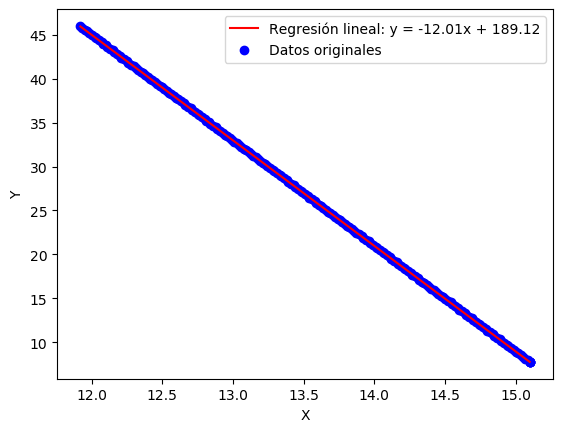

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Datos proporcionados
datos = [
    (15.10, 7.76), (15.10, 7.76), (15.10, 7.76), (15.10, 7.76), (15.10, 7.76),
    (15.09, 7.94), (15.07, 8.14), (15.05, 8.34), (15.04, 8.54), (15.02, 8.74),
    (15.00, 8.93), (14.99, 9.13), (14.97, 9.33), (14.95, 9.53), (14.94, 9.73),
    (14.92, 9.93), (14.90, 10.13), (14.89, 10.33), (14.87, 10.53), (14.85, 10.73),
    (14.84, 10.93), (14.82, 11.13), (14.80, 11.33), (14.79, 11.53), (14.77, 11.72),
    (14.75, 11.92), (14.74, 12.12), (14.72, 12.32), (14.70, 12.52), (14.69, 12.72),
    (14.67, 12.92), (14.65, 13.12), (14.64, 13.32), (14.62, 13.52), (14.60, 13.72),
    (14.59, 13.92), (14.57, 14.12), (14.55, 14.32), (14.54, 14.52), (14.52, 14.71),
    (14.50, 14.91), (14.49, 15.11), (14.47, 15.31), (14.45, 15.51), (14.44, 15.71),
    (14.42, 15.91), (14.40, 16.11), (14.39, 16.31), (14.37, 16.51), (14.35, 16.71),
    (14.34, 16.91), (14.32, 17.11), (14.31, 17.31), (14.29, 17.50), (14.27, 17.70),
    (14.26, 17.90), (14.24, 18.10), (14.22, 18.30), (14.21, 18.50), (14.19, 18.70),
    (14.17, 18.90), (14.16, 19.10), (14.14, 19.30), (14.12, 19.50), (14.11, 19.70),
    (14.09, 19.90), (14.07, 20.10), (14.06, 20.30), (14.04, 20.49), (14.02, 20.69),
    (14.01, 20.89), (13.99, 21.09), (13.97, 21.29), (13.96, 21.49), (13.94, 21.69),
    (13.92, 21.89), (13.91, 22.09), (13.89, 22.29), (13.87, 22.49), (13.86, 22.69),
    (13.84, 22.89), (13.82, 23.09), (13.81, 23.28), (13.79, 23.48), (13.77, 23.68),
    (13.76, 23.88), (13.74, 24.08), (13.72, 24.28), (13.71, 24.48), (13.69, 24.68),
    (13.67, 24.88), (13.66, 25.08), (13.64, 25.28), (13.62, 25.48), (13.61, 25.68),
    (13.59, 25.88), (13.58, 26.08), (13.56, 26.27), (13.54, 26.47), (13.53, 26.67),
    (13.51, 26.87), (13.49, 27.07), (13.48, 27.27), (13.46, 27.47), (13.44, 27.67),
    (13.43, 27.87), (13.41, 28.07), (13.39, 28.27), (13.38, 28.47), (13.36, 28.67),
    (13.34, 28.87), (13.33, 29.06), (13.31, 29.26), (13.29, 29.46), (13.28, 29.66),
    (13.26, 29.86), (13.24, 30.06), (13.23, 30.26), (13.21, 30.46), (13.19, 30.66),
    (13.18, 30.86), (13.16, 31.06), (13.14, 31.26), (13.13, 31.46), (13.11, 31.66),
    (13.09, 31.86), (13.08, 32.05), (13.06, 32.25), (13.04, 32.45), (13.03, 32.65),
    (13.01, 32.85), (12.99, 33.05), (12.98, 33.25), (12.96, 33.45), (12.94, 33.65),
    (12.93, 33.85), (12.91, 34.05), (12.89, 34.25), (12.88, 34.45), (12.86, 34.65),
    (12.84, 34.84), (12.83, 35.04), (12.81, 35.24), (12.80, 35.44), (12.78, 35.64),
    (12.76, 35.84), (12.75, 36.04), (12.73, 36.24), (12.71, 36.44), (12.70, 36.64),
    (12.68, 36.84), (12.66, 37.04), (12.65, 37.24), (12.63, 37.44), (12.61, 37.64),
    (12.60, 37.83), (12.58, 38.03), (12.56, 38.23), (12.55, 38.43), (12.53, 38.63),
    (12.51, 38.83), (12.50, 39.03), (12.48, 39.23), (12.46, 39.43), (12.45, 39.63),
    (12.43, 39.83), (12.41, 40.03), (12.40, 40.23), (12.38, 40.43), (12.36, 40.62),
    (12.35, 40.82), (12.33, 41.02), (12.31, 41.22), (12.30, 41.42), (12.28, 41.62),
    (12.26, 41.82), (12.25, 42.02), (12.23, 42.22), (12.21, 42.42), (12.20, 42.62),
    (12.18, 42.82), (12.16, 43.02), (12.15, 43.22), (12.13, 43.42), (12.11, 43.61),
    (12.10, 43.81), (12.08, 44.01), (12.07, 44.21), (12.05, 44.41), (12.03, 44.61),
    (12.02, 44.81), (12.00, 45.01), (11.98, 45.21), (11.97, 45.41), (11.95, 45.61),
    (11.93, 45.81), (11.92, 46.01)
]


# Separar los datos en X y Y
x = np.array([point[0] for point in datos])
y = np.array([point[1] for point in datos])

# Realizar la regresión lineal
A = np.vstack([x, np.ones(len(x))]).T
m, b = np.linalg.lstsq(A, y, rcond=None)[0]

# Mostrar los resultados
print(f"La pendiente (m) es: {m}")
print(f"La intersección (b) es: {b}")

# Graficar los datos y la línea de regresión
plt.scatter(x, y, color='blue', label='Datos originales')
plt.plot(x, m*x + b, 'r', label=f'Regresión lineal: y = {m:.2f}x + {b:.2f}')
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.show()


## Graficar puntos:

In [2]:
import matplotlib.pyplot as plt

def graficar_puntos(puntos):
    # Separar las coordenadas x e y
    x = [p[0] for p in puntos]
    y = [p[1] for p in puntos]

    # Crear el gráfico
    plt.figure(figsize=(6, 4))
    plt.plot(x, y, marker='o', linestyle='-', color='b')
    
    # Opcional: agregar etiquetas a cada punto
    # for i, (px, py) in enumerate(puntos):
    #     plt.text(px + 0.05, py + 0.05, f'{i}:({px},{py})', fontsize=9)

    plt.title('Gráfico de puntos conectados')
    plt.xlabel('Eje X')
    plt.ylabel('Eje Y')
    plt.grid(True)
    plt.show()

    import re



## Crear automáticamente la distribución de los robots en la arena:

In [1]:

import math

# Parámetros configurables
total_robots = 3        # Número total de robots
num_circles = 3          # Número de circunferencias
initial_radius = 1.0     # Radio del círculo más interno
radius_step = 1        # Diferencia de radio entre círculos
cx, cy = 0, 0            # Centro de las circunferencias

# Distribuir robots por circunferencia
robots_per_circle = [total_robots // num_circles] * num_circles
for i in range(total_robots % num_circles):
    robots_per_circle[i] += 1

robot_id = 0
for circle_index, num_robots in enumerate(robots_per_circle):
    radius = initial_radius + circle_index * radius_step
    for i in range(num_robots):
        # Saltar el ID 4, que está reservado
        if robot_id == 4:
            robot_id += 1
        angle = 2 * math.pi * i / num_robots
        x = cx + radius * math.cos(angle)
        y = cy + radius * math.sin(angle)
        print(f'<foot-bot id="Footbot{robot_id}"><body position="{x:.2f},{y:.2f},0" orientation="0,0,0"/><controller config="lua"/></foot-bot>')
        robot_id += 1


<foot-bot id="Footbot0"><body position="1.00,0.00,0" orientation="0,0,0"/><controller config="lua"/></foot-bot>
<foot-bot id="Footbot1"><body position="2.00,0.00,0" orientation="0,0,0"/><controller config="lua"/></foot-bot>
<foot-bot id="Footbot2"><body position="3.00,0.00,0" orientation="0,0,0"/><controller config="lua"/></foot-bot>


In [26]:
import math

# ==== CONFIGURACIÓN GENERAL ====

centros = [  # Lista de centros y cuántos círculos tiene cada uno
    {"cx": 0, "cy": 0, "num_circles": 2},
    #{"cx": 0  , "cy":  0  , "num_circles": 1},
    #{"cx": 0, "cy": 0, "num_circles": 1},  # Otro conjunto en el mismo centro
]

robots_totales = 10            # Total de robots a distribuir
radio_inicial = 0.5            # Radio del primer círculo
paso_radio = 0.5               # Diferencia de radio entre círculos
id_inicial = 0                 # ID desde el cual comenzar
ids_a_saltar = [0,4]          # IDs reservados que no se deben usar

# ==== CÁLCULO DE REPARTICIÓN ====

# Calcular el total de círculos
total_circulos = sum(c["num_circles"] for c in centros)

# Distribuir robots por círculo de manera balanceada
robots_por_circulo = [robots_totales // total_circulos] * total_circulos
for i in range(robots_totales % total_circulos):
    robots_por_circulo[i] += 1

# ==== GENERACIÓN DE POSICIONES ====

robot_id = id_inicial
circulo_global = 0  # Índice para recorrer robots_por_circulo

for centro in centros:
    cx, cy = centro["cx"], centro["cy"]
    for j in range(centro["num_circles"]):
        radio = radio_inicial + j * paso_radio
        num_robots = robots_por_circulo[circulo_global]
        for i in range(num_robots):
            while robot_id in ids_a_saltar:
                robot_id += 1
            angle = 2 * math.pi * i / num_robots
            x = cx + radio * math.cos(angle)
            y = cy + radio * math.sin(angle)
            print(f'<foot-bot id="Footbot{robot_id}"><body position="{x:.2f},{y:.2f},0" orientation="0,0,0"/><controller config="lua"/></foot-bot>')
            robot_id += 1
        circulo_global += 1


<foot-bot id="Footbot1"><body position="0.50,0.00,0" orientation="0,0,0"/><controller config="lua"/></foot-bot>
<foot-bot id="Footbot2"><body position="0.15,0.48,0" orientation="0,0,0"/><controller config="lua"/></foot-bot>
<foot-bot id="Footbot3"><body position="-0.40,0.29,0" orientation="0,0,0"/><controller config="lua"/></foot-bot>
<foot-bot id="Footbot5"><body position="-0.40,-0.29,0" orientation="0,0,0"/><controller config="lua"/></foot-bot>
<foot-bot id="Footbot6"><body position="0.15,-0.48,0" orientation="0,0,0"/><controller config="lua"/></foot-bot>
<foot-bot id="Footbot7"><body position="1.00,0.00,0" orientation="0,0,0"/><controller config="lua"/></foot-bot>
<foot-bot id="Footbot8"><body position="0.31,0.95,0" orientation="0,0,0"/><controller config="lua"/></foot-bot>
<foot-bot id="Footbot9"><body position="-0.81,0.59,0" orientation="0,0,0"/><controller config="lua"/></foot-bot>
<foot-bot id="Footbot10"><body position="-0.81,-0.59,0" orientation="0,0,0"/><controller config="lu

## Crear imagenes en escala de grises con circulos distribuidos en ella:

In [5]:
from PIL import Image, ImageDraw
import os

# Ruta de guardado
save_path = "/home/jonatand/argos-experiments/Arena"
os.makedirs(save_path, exist_ok=True)

# Define el tamaño del lienzo en píxeles.
tam = 3 #Tamaño de la arena en metros.
canvas_size = (tam*100, tam*100) # Puedes cambiar a (2000, 2000), (3000, 3000), etc. valor en cm.

# El tamaño real de tu arena en metros. ESTO SE MANTIENE CONSTANTE.
arena_size_meters = (tam, tam) # 

# Fondo de la arena (0=negro, 1=blanco)
background_color = 0.5

# El nombre del archivo ahora incluye las dimensiones del lienzo para fácil referencia.
output_file = os.path.join(save_path, "floor_Prueba1.png")


# Lista de círculos: centro (en metros), color normalizado, diámetro en metros
# ¡IMPORTANTE!: Utiliza coo rdenadas y diámetros que estén DENTRO de tu arena de 10x10m.
# Es decir, X e Y deben estar entre -5.0 y +5.0 metros.
# Si usas (5*2.7, -5*1.2), esos puntos están FUERA de la arena de 10x10m.

circulos = [
    {"centro": (-0.6 , 1   ),  "color": 0.25,   "diametro": 0.15},    # gris -> tarea 1
    {"centro": (-0.7 ,-0.35),  "color": 0.25,   "diametro": 0.15},    # gris -> tarea 1
    {"centro": ( 0.75,-0.65),  "color": 0.25,   "diametro": 0.15},    # gris -> tarea 1
    {"centro": ( 0.8 , 0.85),  "color": 0.25,   "diametro": 0.15},    # gris -> tarea 1

    {"centro": (-0.9 , 0.2  ),  "color": 0.85,   "diametro": 0.10},    # gris -> tarea 2
    {"centro": (-0.05 ,-0.65),  "color": 0.85,   "diametro": 0.10},    # gris -> tarea 2
    {"centro": ( 0.95, 0.22 ),  "color": 0.85,   "diametro": 0.10},    # gris -> tarea 2
]


# Crear imagen en modo 'L' (escala de grises), fondo blanco

img = Image.new(
    "L",
    canvas_size,
    color=int(background_color * 255)
)

draw = ImageDraw.Draw(img)

pixels_per_meter = canvas_size[0] / arena_size_meters[0]

# Convertir metros a píxeles
def coord_metros_a_px(x_m, y_m):
    # 'x_m + 5' (o arena_size_meters[0]/2) desplaza el origen (0,0m) al centro de la imagen.
    x_px = int((x_m + arena_size_meters[0] / 2) * pixels_per_meter)
    # '5 - y_m' (o arena_size_meters[1]/2 - y_m) desplaza e invierte el eje Y.
    y_px = int((arena_size_meters[1] / 2 - y_m) * pixels_per_meter)
    return x_px, y_px

# Dibujar cada círculo
for circ in circulos:
    x_m, y_m = circ["centro"]
    color_normalizado = circ["color"]
    diam_m = circ["diametro"]

    # Posición en píxeles (usa el pixels_per_meter calculado)
    x_px, y_px = coord_metros_a_px(x_m, y_m)
    radius_px = int((diam_m / 2) * pixels_per_meter) # También usa pixels_per_meter

    # Color en escala de grises
    gray_color = int(color_normalizado * 255)

    # Definir la caja delimitadora del círculo
    bbox = [
        (x_px - radius_px, y_px - radius_px),
        (x_px + radius_px, y_px + radius_px)
    ]

    # Dibujar el círculo
    draw.ellipse(bbox, fill=gray_color)

# Guardar la imagen
img.save(output_file)
print(f"✅ Imagen guardada como: {output_file}")

✅ Imagen guardada como: /home/jonatand/argos-experiments/Arena/floor_Prueba1.png


## Crear automáticamente datos de prueba para la función global reconstruct